In this section, we will try 3 boosting models: HistGradientBoosting, XGBoost, and LightGBM

In [29]:
import sys
from pathlib import Path
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

In [15]:
sys.path.insert(0, str(Path.cwd().parent))

from src.data_loader import load_data
df_train, df_test = load_data()

from src.preprocessing import prepare_data
X_train, y_train = prepare_data(df_train)

In [ ]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, 
    test_size=0.2, stratify=y_train,
    random_state=42
)

In [ ]:
hgb = HistGradientBoostingClassifier(
    random_state=42
)

hgb.fit(X_fit, y_fit)

y_pred_val = hgb.predict(X_val)

score=accuracy_score(y_val, y_pred_val)

print(f"Le score est de {score}")


Le score est de 0.8570247933884297


We used here the very same fit and val data sets as in the notebook 02_baselinemodels.ipynb, and we can see that the performance on the validation set is slightly below the one of a baseline random forest model.

Let us now tune the hyperparameters to identify which are the ones that have the highest impact on the performance of the model.

In [33]:
from src.preprocessing import build_preprocessor

hgb_pipeline = Pipeline([
    ("processor", build_preprocessor(X_train)),
    ("model", hgb)
])

param_grid = {
    "model__learning_rate":[0.01, 0.05, 0.1, 0.2],
     "model__max_iter":[100, 200, 400]
}

grid = GridSearchCV(
    hgb_pipeline,
    param_grid,
    scoring="accuracy",
    return_train_score=True,
    cv=5,
    n_jobs=-1
)

In [34]:
grid.fit(X_train, y_train)

,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__learning_rate': [0.01, 0.05, ...], 'model__max_iter': [100, 200, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,True
,transformers,"[('scaler', ...), ('binary', ...)]"


In [35]:
grid.best_params_

{'model__learning_rate': 0.2, 'model__max_iter': 400}

In [36]:
grid.best_score_

np.float64(0.8628469178234294)

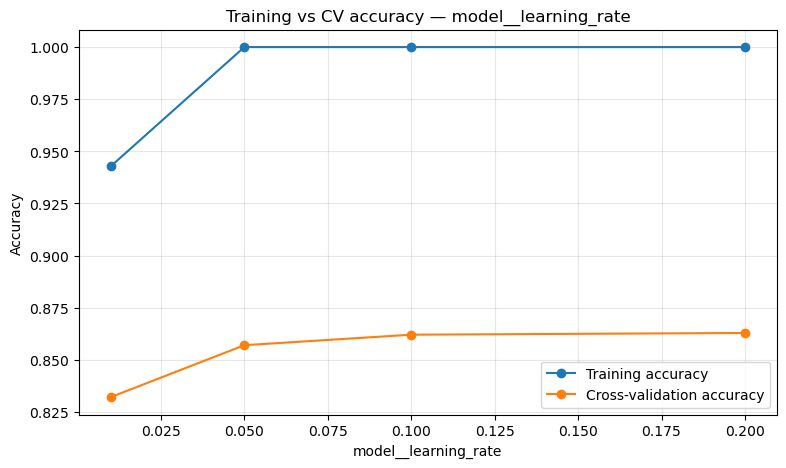

In [41]:
from src.vizualization import plot_hyperparam

plot_hyperparam(grid.cv_results_, 
                param_name="model__learning_rate",
                fixed_params={"model__max_iter": 400}
)

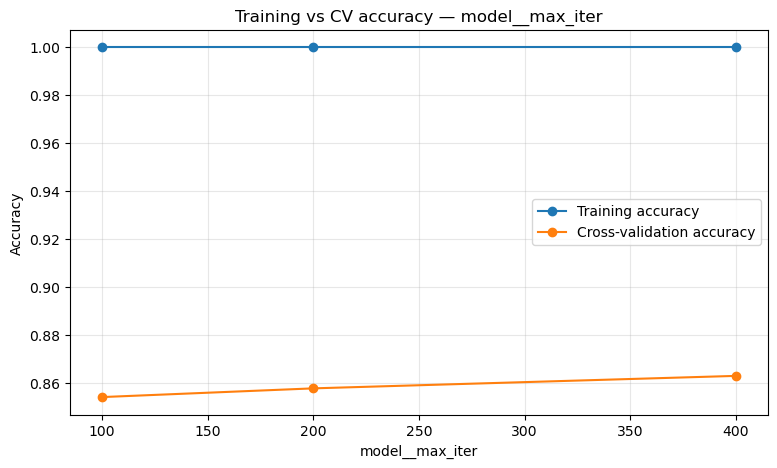

In [42]:
plot_hyperparam(grid.cv_results_, 
                param_name="model__max_iter",
                fixed_params={"model__learning_rate": 0.2}
)